# `TimingPlotter`: reproducing the FSP26 timing breakdown

This notebook needs real CMSSW timing JSON files and won't run out of the
box — see [`quickstart_histograms.ipynb`](quickstart_histograms.ipynb)
instead for an example that works with no external data. It expects,
relative to the current working directory:

    data/Timing/<tag>_NGTScouting_16j_16t_16s.json

for every `<tag>` in `CONFIGURATIONS` below. This reproduces the stacked
timing-breakdown plot from `PixelTrackingPhase2/Conferences-Publications/FSP26/makePlots_TimingBars.py`
in the main `PhD-mission` repo — same configurations, same bundled
`"tracking"` grouping, same broken y-axis for the `Legacy` bar.


In [1]:
from cmsplot import setStyle
from cmsplot.timing import TimingPlotter, load_grouping, load_modules_json

setStyle(customized=False)

## Configurations and grouping

`CONFIGURATIONS` maps each config tag to its legend/axis label (see
`data/Timing/` for the exact tags available). The module-grouping patterns
and colors aren't redefined here — `load_grouping("tracking")` pulls the
bundled, ready-to-use grouping shipped with `cmsplot` (see the main
`README.md`'s "Timing breakdown plots" section, or `available_groupings()`
for what else is bundled).

In [2]:
CONFIGURATIONS = {
    "LegacyBaseline":  "Legacy\n[2 iterations]",
    "CurrentBaseline": "Tracking baseline\n[1 iteration]",
    "ITACA":           "ITACA\n[2 GPU iterations]",
}

grouping = load_grouping("tracking")
grouping

Grouping('tracking', classifier='membership', 1007 patterns, 9 categories)

## Loading

`loadModules` points at one JSON file per config tag; `Nevents` is the event
count the Tracking-sequence modules actually ran on for this dataset (passed
explicitly rather than guessed from an arbitrary module index — see the
`TimingPlotter`/`load_grouping` docstrings for why).

In [3]:
NEVENTS = 39744

plotter = TimingPlotter(
    CONFIGURATIONS=CONFIGURATIONS,
    loadModules=lambda tag: load_modules_json(
        f"data/Timing/{tag}_NGTScouting_16j_16t_16s.json"
    ),
    classify=grouping.classify(),
    Nevents=NEVENTS,
)

'LegacyBaseline': 308 module(s) did not match any group (55.3% of total time) - see .unmatchedModules('LegacyBaseline')
'CurrentBaseline': 308 module(s) did not match any group (85.5% of total time) - see .unmatchedModules('CurrentBaseline')
'ITACA': 306 module(s) did not match any group (95.4% of total time) - see .unmatchedModules('ITACA')


Sanity-check what got loaded before plotting — `unmatchedModules` covers
modules outside the Tracking sequence entirely (ECAL, muons, other HLT
paths, ...), which is expected and not a sign anything is missing.

In [4]:
plotter.listGroups("LegacyBaseline")


Config: LegacyBaseline
  [Tracking] IT Hits              0.1932 s/event
  [Tracking] Data Conversion      0.1032 s/event
  [Tracking] OT Hits              0.00647 s/event
  [Tracking] Track Seeding        2.407 s/event
  [Tracking] Track Building       1.567 s/event
  [Tracking] Track Fitting        0.5569 s/event
  [Tracking] Track Selection      0.02013 s/event
  [Tracking] Masking              0.001879 s/event


## Plotting

`Legacy` is dominated by the old CKF-based seeding and is several times
slower than the other two configurations, so a plain `yLim` would either
clip it or squeeze the other bars flat — `breakYLim=True` auto-sizes a
broken y-axis for it instead, exactly as in the original script.

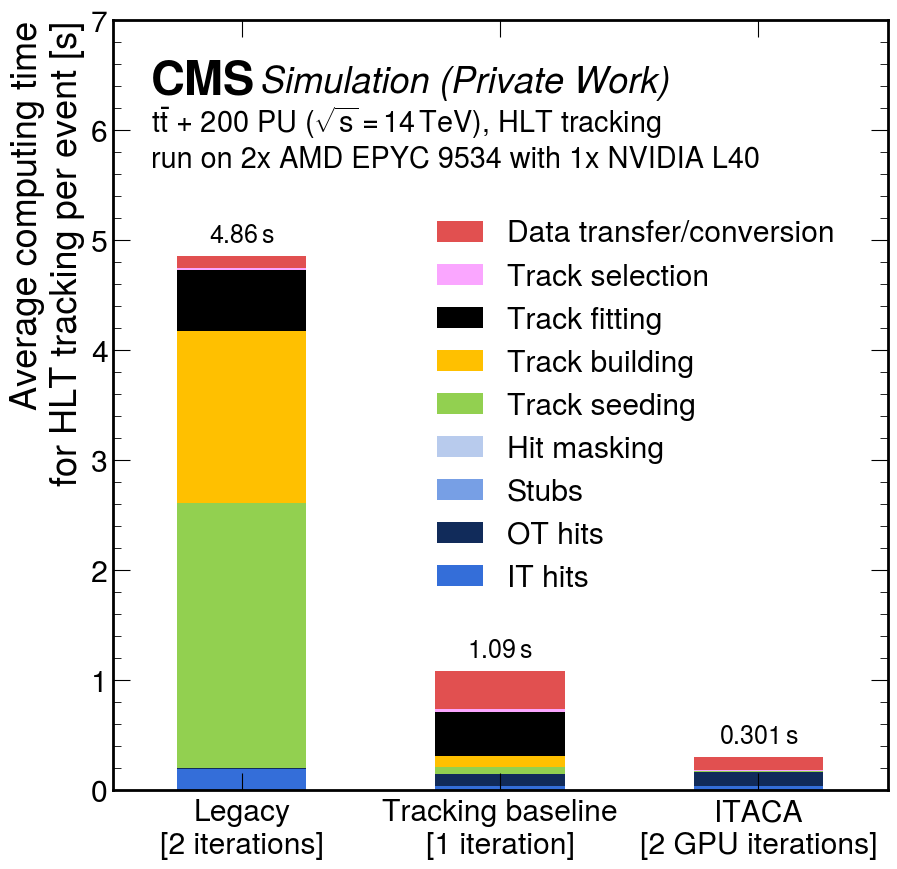

In [5]:
plotter.setPlottingConfiguration(
    CMSLABEL="Simulation (Private Work)",
    DATALABEL=(
        r"$\text{t}\bar{\text{t}}$ + 200 PU ($\sqrt{s} = 14\,\text{TeV}$), HLT tracking"
        "\nrun on 2x AMD EPYC 9534 with 1x NVIDIA L40"
    ),
    DIR="plots/timing/NGTScouting",
    YLABEL="Average computing time\nfor HLT tracking per event [s]",
    SAVEAS=["png", "pdf"],
)

fig, ax = plotter.plotStackedTiming(
    steps=grouping.step,
    categories=grouping.categories,
    colors=grouping.colors,
    yLim=(0, 7),
    figsize=(10, 10),
    legendBboxToAnchor=(0.97, 0.78),
    filename="bar_tracking",
)

## Next steps

- `TrackingDQMPlotter_example.ipynb` covers the DQM validation plotters
  against the same kind of real data.
- `SecondaryVertexingDQMPlotter_example.py` and the main `README.md` cover
  the rest of `cmsplot.timing`'s API (`classify_by_step_prefix` for
  multi-step studies, writing a custom grouping, the `PLOTTINGCONFIGURATION`
  overlay options shared with the DQM plotters).
